In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv('Pv_loc_train.csv')
data = data.set_index('Sample')

target = data.loc[:, "Continent"]
target = target.replace({'SE_Asia':0, 'America':1, 'Asia':10, 'Africa':11}).astype(int) 
data_predictors = data.loc[:, data.columns != "Continent"]

In [ ]:
test_data = pd.read_csv('Pv_loc_test.csv')
test_data = test_data.set_index('Sample')

y_test = test_data.loc[:, "Continent"]
y_test = y_test.replace({'SE_Asia':0, 'America':1, 'Asia':10, 'Africa':11}).astype(int)
x_test = test_data.loc[:, test_data.columns != "Continent"]

In [ ]:
target.unique()

array([ 0,  1, 10, 11])

In [ ]:
def svm_test(features):
    grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"),
                        {"C": [0.01, 0.1, 1, 10, 100],
                         "gamma": ["scale", 0.001, 0.01, 0.1, 1]},
                        cv=inner, scoring="f1_macro")            # use "f1_macro" for multiclass
    grid.fit(data_predictors[features], target)       # tunes on the training set, then refits the best model on all of it
    y_pred = grid.predict(x_test[features]) 
    
    score = f1_score(y_test, y_pred, average = 'macro')  
    
    matrix = confusion_matrix(y_test, y_pred, labels=sorted(target.unique())) 

    return score, matrix

In [ ]:
mrmr_barcode_scores = {}

mrmr_matrices = {}

barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

for length in barcode_lengths: 
    with open(f"MRMR_subsets/top_{length}_MRMR") as f:
        features = f.read().splitlines()
    score, matrix = svm_test(features)
    mrmr_matrices[length] = matrix
    mrmr_barcode_scores[length] = score

In [ ]:
moremore = []
for length in barcode_lengths: 
    qual = mrmr_barcode_scores[length]
    moremore.append(qual)
    
moremore

[0.5214285714285715,
 0.6333333333333333,
 0.5321808510638297,
 0.8333333333333333,
 0.9142857142857143,
 0.833966565349544,
 1.0,
 1.0,
 1.0,
 1.0]

In [ ]:
gb_barcode_scores = {}

gb_matrices = {}

for length in barcode_lengths: 
    with open(f"GB_subsets/top_{length}_GB.txt") as f:
        features = f.read().splitlines()
    score, matrix = svm_test(features)
    gb_matrices[length] = matrix
    gb_barcode_scores[length] = score 

In [ ]:
greatb = []
for length in barcode_lengths: 
    qual = gb_barcode_scores[length]
    greatb.append(qual)
    
greatb

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [ ]:
ga_barcode_scores = {}

ga_matrices = {}

for length in barcode_lengths: 
    with open(f"GA_subsets/top_{length}_GA.txt") as f:
        features = f.read().splitlines()
    score, matrix = svm_test(features)
    ga_matrices[length] = matrix
    ga_barcode_scores[length] = score 

In [ ]:
goona = []
for length in barcode_lengths: 
    qual = ga_barcode_scores[length]
    goona.append(qual)
    
goona

[0.9142857142857143,
 0.9479166666666667,
 1.0,
 0.7696808510638298,
 0.9142857142857144,
 0.7391304347826086,
 0.945054945054945,
 0.9142857142857144,
 1.0,
 0.8333333333333333]

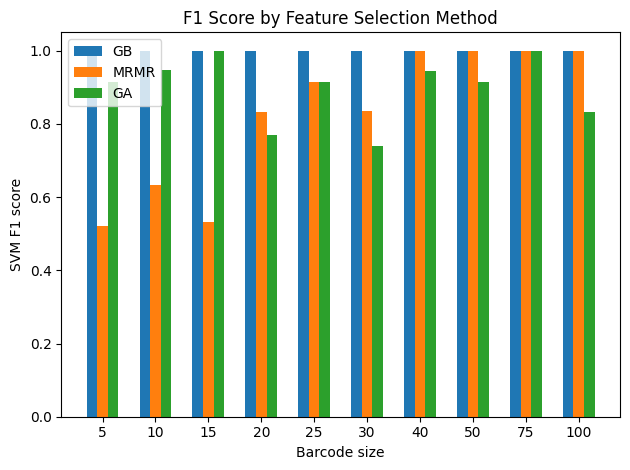

In [ ]:
# Bar positions and width
x = np.arange(len(barcode_lengths))
width = 0.2

# Plot bars
plt.bar(x - width, gb_barcode_scores.values(), width, label='GB')
plt.bar(x, mrmr_barcode_scores.values(), width, label='MRMR')
plt.bar(x + width, ga_barcode_scores.values(), width, label='GA')

# Labels and formatting
plt.xlabel('Barcode size')
plt.ylabel('SVM F1 score')
plt.title('F1 Score by Feature Selection Method')
plt.xticks(x, barcode_lengths)
plt.legend()
plt.tight_layout()

plt.show()

In [ ]:
ga_matrices[10]

In [ ]:
labels = ['SE_Asia', 'America', 'Asia', 'Africa']

conf_table = pd.DataFrame(
    confusion_matrix_array,
    index=labels,
    columns=labels
)

print(conf_table)